# Sàng lọc nguy cơ trễ hạn thanh toán thẻ tín dụng

Notebook học máy tái lập được, dùng để **ưu tiên hỗ trợ và nhắc thanh toán**. Không được dùng cho việc tự động từ chối tín dụng, định giá, phạt hay bất kỳ quyết định có tác động lớn nào.

**Quy trình:** tải dữ liệu → kiểm tra chất lượng → chia tập không rò rỉ → baseline → chọn ngưỡng trên validation → đánh giá test một lần → calibration và audit theo nhóm → API tùy chọn.

## 1. Thiết lập

Chạy ô bên dưới một lần trong môi trường sạch. Dữ liệu thô UCI sẽ được tải khi chạy notebook và không được nhúng sẵn vào tệp này.

In [1]:
# Uncomment when packages are not installed:
# %pip install pandas scikit-learn matplotlib joblib ucimlrepo fastapi uvicorn

from pathlib import Path
import json
import platform
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, roc_auc_score,
                             PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
TARGET = 'default_next_month'
MODEL_FEATURES = ['LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_AMT1', 'BILL_AMT1']
AUDIT_COLUMNS = ['SEX', 'EDUCATION', 'MARRIAGE']
ARTIFACT_DIR = Path('artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)
print(f'Python {platform.python_version()} | random seed={SEED}')

Python 3.12.10 | random seed=42


## 0. Đóng băng đặc tả trước khi xem test

Không thay đổi định nghĩa bài toán, thời điểm dự đoán hay tiêu chí đánh giá sau khi xem tập test. Ô này là bản ghi quyết định trước thí nghiệm.

In [2]:
EXPERIMENT_SPEC = {
    'problem': 'Phân loại nhị phân: nguy cơ vỡ nợ trong tháng kế tiếp',
    'prediction_time': 'Thời điểm chốt dữ liệu, trước tháng mục tiêu',
    'intended_use': 'Ưu tiên nhắc thanh toán hoặc đề xuất hỗ trợ tài chính tự nguyện',
    'prohibited_use': 'Không dùng để duyệt/từ chối tín dụng, định giá, phạt hoặc quyết định tự động',
    'primary_metric': 'PR-AUC',
    'secondary_metrics': ['ROC-AUC', 'recall lớp default', 'precision', 'Brier score', 'calibration'],
    'test_rule': 'Chỉ dùng một lần cho báo cáo cuối cùng'
}
print(json.dumps(EXPERIMENT_SPEC, ensure_ascii=False, indent=2))

{
  "problem": "Phân loại nhị phân: nguy cơ vỡ nợ trong tháng kế tiếp",
  "prediction_time": "Thời điểm chốt dữ liệu, trước tháng mục tiêu",
  "intended_use": "Ưu tiên nhắc thanh toán hoặc đề xuất hỗ trợ tài chính tự nguyện",
  "prohibited_use": "Không dùng để duyệt/từ chối tín dụng, định giá, phạt hoặc quyết định tự động",
  "primary_metric": "PR-AUC",
  "secondary_metrics": [
    "ROC-AUC",
    "recall lớp default",
    "precision",
    "Brier score",
    "calibration"
  ],
  "test_rule": "Chỉ dùng một lần cho báo cáo cuối cùng"
}


## 2. Tải và khảo sát dữ liệu

Bộ dữ liệu: UCI Default of Credit Card Clients (mã 350). Biến mục tiêu là trạng thái vỡ nợ trong tháng kế tiếp. Hãy kiểm tra giấy phép và trích dẫn của UCI trước khi công bố kết quả.

In [3]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [4]:
from ucimlrepo import fetch_ucirepo

uci = fetch_ucirepo(id=350)
X_raw = uci.data.features.copy()
y_raw = uci.data.targets.copy()

# Chuẩn hóa các biến thể tên cột mà UCI/ucimlrepo có thể trả về.
X_raw.columns = [str(column).strip().upper() for column in X_raw.columns]
if 'PAY_0' not in X_raw.columns and 'PAY_1' in X_raw.columns:
    X_raw = X_raw.rename(columns={'PAY_1': 'PAY_0'})
if all(f'X{i}' in X_raw.columns for i in range(1, 24)):
    uci_x_mapping = {
        'X1': 'LIMIT_BAL', 'X2': 'SEX', 'X3': 'EDUCATION', 'X4': 'MARRIAGE', 'X5': 'AGE',
        'X6': 'PAY_0', 'X7': 'PAY_2', 'X8': 'PAY_3', 'X9': 'PAY_4', 'X10': 'PAY_5', 'X11': 'PAY_6',
        'X12': 'BILL_AMT1', 'X13': 'BILL_AMT2', 'X14': 'BILL_AMT3', 'X15': 'BILL_AMT4', 'X16': 'BILL_AMT5', 'X17': 'BILL_AMT6',
        'X18': 'PAY_AMT1', 'X19': 'PAY_AMT2', 'X20': 'PAY_AMT3', 'X21': 'PAY_AMT4', 'X22': 'PAY_AMT5', 'X23': 'PAY_AMT6'
    }
    X_raw = X_raw.rename(columns=uci_x_mapping)

df = pd.concat([X_raw, y_raw.rename(columns={y_raw.columns[0]: TARGET})], axis=1)
missing_features = sorted(set(MODEL_FEATURES) - set(df.columns))
if missing_features:
    raise ValueError(f'Thiếu cột: {missing_features}. Cột UCI hiện có: {X_raw.columns.tolist()}')
assert df[TARGET].isin([0, 1]).all(), 'Target must be binary.'
print(f'Rows: {len(df):,}; columns: {df.shape[1]}')
display(df.head())
display(pd.DataFrame({'missing': df.isna().sum(), 'dtype': df.dtypes.astype(str)}))
display(df[TARGET].value_counts(normalize=True).rename('class_share'))

Rows: 30,000; columns: 24


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_next_month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


,missing,dtype
LIMIT_BAL,0,int64
SEX,0,int64
EDUCATION,0,int64
MARRIAGE,0,int64
AGE,0,int64
PAY_0,0,int64
PAY_2,0,int64
PAY_3,0,int64
PAY_4,0,int64
PAY_5,0,int64


default_next_month
0    0.7788
1    0.2212
Name: class_share, dtype: float64

In [5]:
# Kiểm tra schema, số dòng, khóa và chất lượng trước khi chia tập.
expected_columns = set(MODEL_FEATURES + AUDIT_COLUMNS + [TARGET])
assert expected_columns.issubset(df.columns), 'Schema không đủ các cột cần thiết.'
key_column = 'ID' if 'ID' in df.columns else None
quality_report = {
    'rows': len(df), 'columns': len(df.columns), 'missing_cells': int(df.isna().sum().sum()),
    'duplicate_rows': int(df.duplicated().sum()), 'key_column': key_column,
    'duplicate_keys': int(df[key_column].duplicated().sum()) if key_column else None
}
print(json.dumps(quality_report, ensure_ascii=False, indent=2))
assert quality_report['missing_cells'] == 0, 'Xử lý missing phải được ghi nhận trước khi tiếp tục.'
assert quality_report['duplicate_keys'] in (0, None), 'Khóa bản ghi không được trùng.'

{
  "rows": 30000,
  "columns": 24,
  "missing_cells": 0,
  "duplicate_rows": 35,
  "key_column": null,
  "duplicate_keys": null
}


## 3. Chia train / validation / test không rò rỉ dữ liệu

Mọi phép biến đổi và huấn luyện mô hình chỉ diễn ra sau bước chia này. Tập test được giữ nguyên cho đến phần đánh giá cuối cùng.

In [6]:
train_val, test = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=SEED)
train, validation = train_test_split(train_val, test_size=0.25, stratify=train_val[TARGET], random_state=SEED)
print({'train': len(train), 'validation': len(validation), 'test': len(test)})

# Sensitive columns are audit-only, and ID is never used as a feature.
assert not set(AUDIT_COLUMNS).intersection(MODEL_FEATURES)
assert 'ID' not in MODEL_FEATURES

{'train': 18000, 'validation': 6000, 'test': 6000}


## 3a. EDA chỉ trên tập train

Các biểu đồ dưới đây phục vụ quyết định tiền xử lý và hiểu mất cân bằng lớp; không dùng validation hoặc test để định hướng EDA.

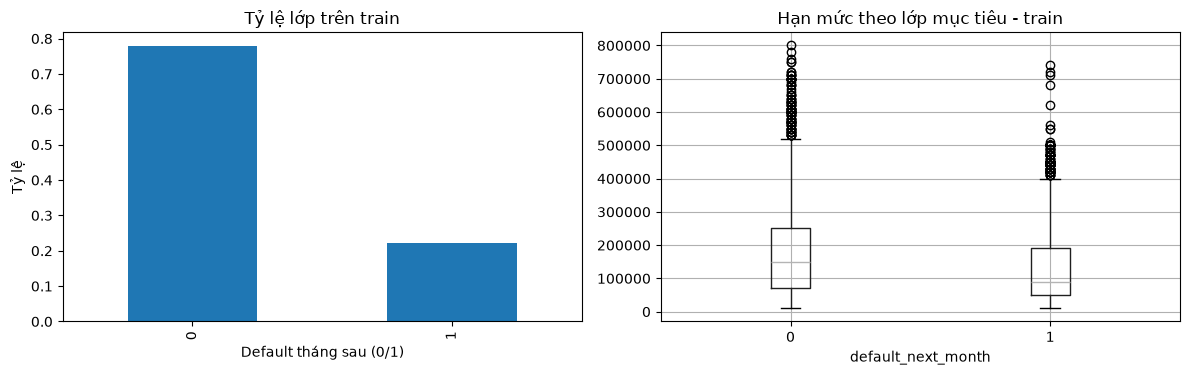

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,18000.0,167373.111111,129566.755366,10000.0,50000.00,140000.0,240000.00,800000.0
PAY_0,18000.0,-0.010889,1.116321,-2.0,-1.00,0.0,0.00,8.0
PAY_2,18000.0,-0.134222,1.196782,-2.0,-1.00,0.0,0.00,8.0
PAY_3,18000.0,-0.165500,1.197066,-2.0,-1.00,0.0,0.00,8.0
PAY_AMT1,18000.0,5645.855778,16793.985692,0.0,1000.00,2100.0,5009.00,873552.0
BILL_AMT1,18000.0,50619.208611,72362.398491,-165580.0,3455.75,22339.0,66541.25,621749.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train[TARGET].value_counts(normalize=True).sort_index().plot(kind='bar', ax=axes[0], title='Tỷ lệ lớp trên train')
axes[0].set_xlabel('Default tháng sau (0/1)'); axes[0].set_ylabel('Tỷ lệ')
train.boxplot(column='LIMIT_BAL', by=TARGET, ax=axes[1])
axes[1].set_title('Hạn mức theo lớp mục tiêu - train'); plt.suptitle('')
plt.tight_layout(); plt.show()
display(train[MODEL_FEATURES].describe().T)
# Quyết định: median imputation + chuẩn hóa trong Pipeline; không oversample trước khi chia tập.

## 3b. CV trên train và độ biến thiên theo fold

CV chỉ sử dụng train. Mean ± độ lệch chuẩn giữa các fold được báo cáo để thể hiện mức biến thiên; kết quả này không được thay bằng đánh giá test cuối.

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_pipeline = Pipeline([
    ('preprocess', ColumnTransformer([('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), MODEL_FEATURES)])),
    ('model', LogisticRegression(max_iter=2000, random_state=SEED))
])
cv_result = cross_validate(cv_pipeline, train[MODEL_FEATURES], train[TARGET], cv=cv, scoring={'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'})
cv_summary = pd.DataFrame({'PR-AUC': cv_result['test_pr_auc'], 'ROC-AUC': cv_result['test_roc_auc']})
display(cv_summary)
print('Biến thiên qua fold (mean ± std):')
display(pd.DataFrame({'mean': cv_summary.mean(), 'std': cv_summary.std()}))

,PR-AUC,ROC-AUC
0,0.501658,0.729237
1,0.507058,0.714687
2,0.526453,0.727919
3,0.528846,0.744039
4,0.485977,0.713818


Biến thiên qua fold (mean ± std):


,mean,std
PR-AUC,0.509998,0.017897
ROC-AUC,0.725940,0.012409


## 4. Mô hình và chọn ngưỡng trên validation

So sánh baseline luôn dự đoán không vỡ nợ với logistic regression không trọng số và có cân bằng lớp. Ngưỡng được chọn bằng dữ liệu validation theo chi phí minh bạch; chỉ thay đổi giả định chi phí trước khi đánh giá test cuối cùng.

In [9]:
def make_pipeline(class_weight=None):
    preprocess = ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), MODEL_FEATURES)
    ], remainder='drop')
    return Pipeline([
        ('preprocess', preprocess),
        ('model', LogisticRegression(max_iter=2000, class_weight=class_weight, random_state=SEED))
    ])

def choose_threshold(y_true, probabilities, false_negative_cost=5.0, false_positive_cost=1.0):
    y_true, probabilities = np.asarray(y_true), np.asarray(probabilities)
    candidates = np.arange(0.05, 0.96, 0.05)
    costs = []
    for threshold in candidates:
        predicted = probabilities >= threshold
        fn = np.sum((y_true == 1) & ~predicted)
        fp = np.sum((y_true == 0) & predicted)
        costs.append(false_negative_cost * fn + false_positive_cost * fp)
    index = int(np.argmin(costs))
    return float(candidates[index]), float(costs[index])

def metrics(y_true, probabilities, threshold):
    predicted = probabilities >= threshold
    return {
        'roc_auc': float(roc_auc_score(y_true, probabilities)),
        'pr_auc': float(average_precision_score(y_true, probabilities)),
        'recall': float(recall_score(y_true, predicted, zero_division=0)),
        'precision': float(precision_score(y_true, predicted, zero_division=0)),
        'brier_score': float(brier_score_loss(y_true, probabilities))
    }

COST_FN, COST_FP = 5.0, 1.0
baseline_accuracy = float((validation[TARGET] == 0).mean())
candidates = {}
for name, weight in {'unweighted_logistic': None, 'balanced_logistic': 'balanced'}.items():
    pipeline = make_pipeline(weight)
    pipeline.fit(train[MODEL_FEATURES], train[TARGET])
    probabilities = pipeline.predict_proba(validation[MODEL_FEATURES])[:, 1]
    threshold, cost = choose_threshold(validation[TARGET], probabilities, COST_FN, COST_FP)
    candidates[name] = {'pipeline': pipeline, 'threshold': threshold, 'cost': cost, 'metrics': metrics(validation[TARGET], probabilities, threshold)}

summary = pd.DataFrame({name: {'threshold': value['threshold'], 'validation_cost': value['cost'], **value['metrics']} for name, value in candidates.items()}).T
print(f'Always-non-default validation accuracy: {baseline_accuracy:.3f}')
display(summary)
selected_name = summary['validation_cost'].astype(float).idxmin()
selected = candidates[selected_name]
print(f'Selected on validation only: {selected_name} at threshold={selected["threshold"]:.2f}')

Always-non-default validation accuracy: 0.779


,threshold,validation_cost,roc_auc,pr_auc,recall,precision,brier_score
unweighted_logistic,0.2,3869.0,0.717448,0.491839,0.708365,0.327070,0.146533
balanced_logistic,0.5,3784.0,0.717797,0.490320,0.648078,0.372456,0.206908


Selected on validation only: balanced_logistic at threshold=0.50


## 4a. Bốn thí nghiệm bắt buộc trên validation

Các so sánh dưới đây dùng chung split validation và cùng đơn vị đánh giá. Chúng phục vụ chọn mô hình/ngưỡng; không dùng test để chọn.

In [10]:
# Thí nghiệm 1: so sánh accuracy với PR-AUC và recall.
experiment_rows = []
always_non_default = np.zeros(len(validation), dtype=int)
experiment_rows.append({
    'mô_hình': 'Baseline: luôn không-default',
    'accuracy': float((always_non_default == validation[TARGET].to_numpy()).mean()),
    'PR-AUC': np.nan,
    'recall_default': 0.0,
    'precision': 0.0
})
for name, result in candidates.items():
    p = result['pipeline'].predict_proba(validation[MODEL_FEATURES])[:, 1]
    pred = p >= result['threshold']
    experiment_rows.append({
        'mô_hình': name, 'accuracy': float((pred == validation[TARGET].to_numpy()).mean()),
        'PR-AUC': float(average_precision_score(validation[TARGET], p)),
        'recall_default': float(recall_score(validation[TARGET], pred, zero_division=0)),
        'precision': float(precision_score(validation[TARGET], pred, zero_division=0))
    })
experiment_1 = pd.DataFrame(experiment_rows)
display(experiment_1)
print('Lưu ý: accuracy cao của baseline có thể che giấu recall = 0 cho lớp default.')

,mô_hình,accuracy,PR-AUC,recall_default,precision
0,Baseline: luôn không-default,0.778833,NaN,0.000000,0.000000
1,unweighted_logistic,0.613167,0.491839,0.708365,0.327070
2,balanced_logistic,0.680667,0.490320,0.648078,0.372456


Lưu ý: accuracy cao của baseline có thể che giấu recall = 0 cho lớp default.


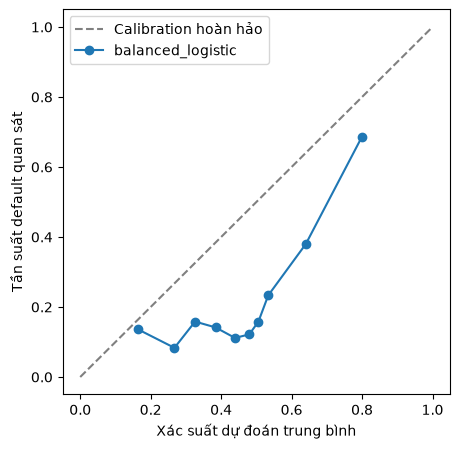

Brier score validation: 0.2069


In [11]:
# Thí nghiệm 2: calibration của mô hình được chọn trên validation.
selected_validation_p = selected['pipeline'].predict_proba(validation[MODEL_FEATURES])[:, 1]
observed_val, predicted_val = calibration_curve(validation[TARGET], selected_validation_p, n_bins=10, strategy='quantile')
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], '--', color='gray', label='Calibration hoàn hảo')
plt.plot(predicted_val, observed_val, marker='o', label=selected_name)
plt.xlabel('Xác suất dự đoán trung bình'); plt.ylabel('Tần suất default quan sát'); plt.legend(); plt.show()
print('Brier score validation:', round(brier_score_loss(validation[TARGET], selected_validation_p), 4))

,ngưỡng,false_negative,false_positive,"chi_phí (FN=5.0, FP=1.0)",recall_default
0,0.2,82,4159,4569.0,0.938206
1,0.5,467,1449,3784.0,0.648078
2,0.8,1148,77,5817.0,0.134891


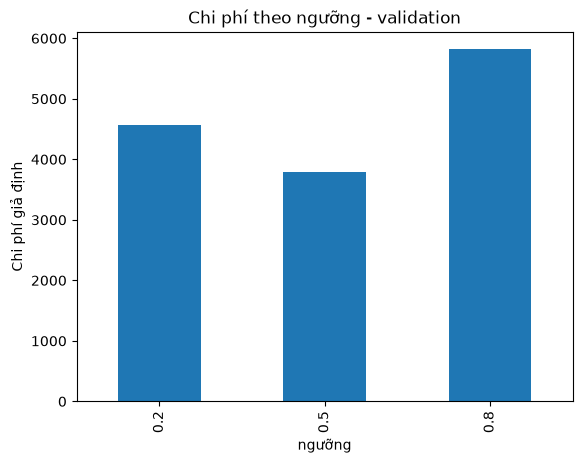

In [12]:
# Thí nghiệm 3: so sánh 3 ngưỡng và chi phí trên validation.
threshold_rows = []
for threshold in [0.20, 0.50, 0.80]:
    pred = selected_validation_p >= threshold
    false_negative = int(((validation[TARGET].to_numpy() == 1) & ~pred).sum())
    false_positive = int(((validation[TARGET].to_numpy() == 0) & pred).sum())
    threshold_rows.append({
        'ngưỡng': threshold, 'false_negative': false_negative, 'false_positive': false_positive,
        f'chi_phí (FN={COST_FN}, FP={COST_FP})': COST_FN * false_negative + COST_FP * false_positive,
        'recall_default': float(recall_score(validation[TARGET], pred, zero_division=0))
    })
experiment_3 = pd.DataFrame(threshold_rows)
display(experiment_3)
experiment_3.plot(x='ngưỡng', y=f'chi_phí (FN={COST_FN}, FP={COST_FP})', kind='bar', legend=False, title='Chi phí theo ngưỡng - validation')
plt.ylabel('Chi phí giả định'); plt.show()

## 5. Đánh giá cuối trên test — chỉ chạy một lần

Không tinh chỉnh tham số, đặc trưng, ngưỡng hoặc giả định chi phí sau khi xem kết quả này.

{
  "roc_auc": 0.7010421264326759,
  "pr_auc": 0.484014797789794,
  "recall": 0.6269781461944235,
  "precision": 0.36443276390713975,
  "brier_score": 0.20958710691599625
}
Confusion matrix [rows=true, columns=predicted]:
[[3222 1451]
 [ 495  832]]


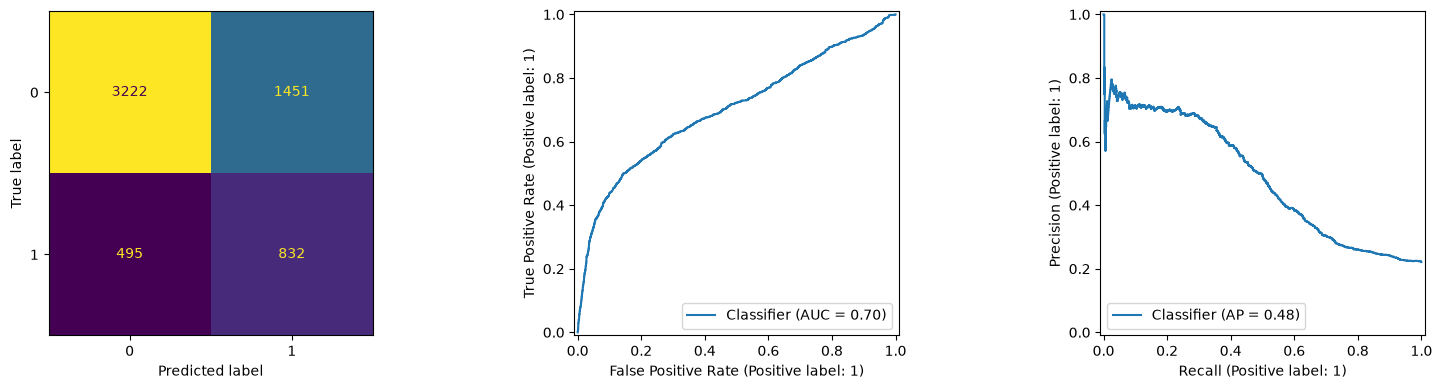

In [13]:
test_probabilities = selected['pipeline'].predict_proba(test[MODEL_FEATURES])[:, 1]
test_threshold = selected['threshold']
test_predictions = test_probabilities >= test_threshold
test_metrics = metrics(test[TARGET], test_probabilities, test_threshold)
print(json.dumps(test_metrics, indent=2))
print('Confusion matrix [rows=true, columns=predicted]:')
print(confusion_matrix(test[TARGET], test_predictions))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(test[TARGET], test_predictions, ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(test[TARGET], test_probabilities, ax=axes[1])
PrecisionRecallDisplay.from_predictions(test[TARGET], test_probabilities, ax=axes[2])
plt.tight_layout()
plt.show()

## 6. Calibration và audit sai số theo nhóm

Audit giúp phát hiện khác biệt giữa các nhóm, nhưng không chứng minh tính công bằng hay quan hệ nhân quả. Không dùng thuộc tính nhạy cảm làm đầu vào mô hình nếu chưa có lý do được ghi nhận và phê duyệt.

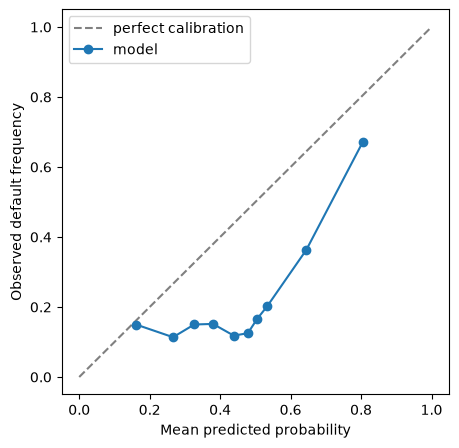

,attribute,value,n,outreach_rate,recall
0,SEX,1,2402,0.414654,0.652406
1,SEX,2,3598,0.357699,0.608355
2,EDUCATION,0,2,1.000000,0.000000
3,EDUCATION,1,2130,0.275587,0.548148
4,EDUCATION,2,2774,0.445205,0.690549
5,EDUCATION,3,1014,0.440828,0.597701
6,EDUCATION,4,26,0.153846,1.000000
7,EDUCATION,5,45,0.111111,0.000000
8,EDUCATION,6,9,0.333333,0.000000
9,MARRIAGE,0,7,0.142857,0.000000


The dataset is observational and cannot establish causal effects.
• Performance may not generalize to other populations, periods, or business processes.
• This model supports voluntary outreach triage only, never credit approval, pricing, penalties, or automated adverse action.


In [14]:
observed, predicted = calibration_curve(test[TARGET], test_probabilities, n_bins=10, strategy='quantile')
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], '--', color='gray', label='perfect calibration')
plt.plot(predicted, observed, marker='o', label='model')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed default frequency'); plt.legend(); plt.show()

audit = []
for column in AUDIT_COLUMNS:
    for value, group in test.assign(_prediction=test_predictions).groupby(column, dropna=False):
        positives = group[TARGET].sum()
        audit.append({
            'attribute': column, 'value': str(value), 'n': len(group),
            'outreach_rate': float(group['_prediction'].mean()),
            'recall': float(((group[TARGET] == 1) & group['_prediction']).sum() / max(positives, 1))
        })
audit_df = pd.DataFrame(audit)
display(audit_df)

limitations = [
    'The dataset is observational and cannot establish causal effects.',
    'Performance may not generalize to other populations, periods, or business processes.',
    'This model supports voluntary outreach triage only, never credit approval, pricing, penalties, or automated adverse action.'
]
print(*limitations, sep='\n• ')

## 7. Lưu pipeline và báo cáo tái lập

Đối tượng được lưu gồm cả tiền xử lý và mô hình, nhờ đó phần phục vụ sử dụng đúng các phép biến đổi như khi huấn luyện.

In [15]:
joblib.dump(selected['pipeline'], ARTIFACT_DIR / 'risk_pipeline.joblib')
report = {
    'selected_model': selected_name, 'features': MODEL_FEATURES, 'threshold': test_threshold,
    'cost_assumptions': {'false_negative': COST_FN, 'false_positive': COST_FP},
    'split_sizes': {'train': len(train), 'validation': len(validation), 'test': len(test)},
    'validation_candidates': {name: {'threshold': result['threshold'], 'cost': result['cost'], **result['metrics']} for name, result in candidates.items()},
    'test_metrics': test_metrics,
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(),
    'limitations': limitations
}
(ARTIFACT_DIR / 'metrics.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
print('Saved:', ARTIFACT_DIR / 'risk_pipeline.joblib', 'and', ARTIFACT_DIR / 'metrics.json')

Saved: artifacts\risk_pipeline.joblib and artifacts\metrics.json


## 8. API FastAPI tùy chọn

Ô này minh họa API chạy cục bộ. API kiểm tra dữ liệu đầu vào và không lưu chúng. Chỉ chạy sau khi đã lưu pipeline; sau đó dùng `uvicorn` trong terminal để phục vụ ứng dụng.

In [16]:
# Optional API source; keep this cell as a reference or export it to api.py.
from fastapi import FastAPI
from pydantic import BaseModel, Field

app = FastAPI(title='Credit Card Default Risk Lab')
api_pipeline = joblib.load(ARTIFACT_DIR / 'risk_pipeline.joblib')

class RiskInput(BaseModel):
    limit_bal: float = Field(ge=10_000, le=1_000_000)
    pay_0: int = Field(ge=-2, le=9)
    pay_2: int = Field(ge=-2, le=9)
    pay_3: int = Field(ge=-2, le=9)
    pay_amt1: float = Field(ge=0, le=2_000_000)
    bill_amt1: float = Field(ge=-500_000, le=2_000_000)

@app.post('/api/risk-score')
def score_risk(payload: RiskInput):
    row = pd.DataFrame([{
        'LIMIT_BAL': payload.limit_bal, 'PAY_0': payload.pay_0, 'PAY_2': payload.pay_2,
        'PAY_3': payload.pay_3, 'PAY_AMT1': payload.pay_amt1, 'BILL_AMT1': payload.bill_amt1
    }])
    probability = float(api_pipeline.predict_proba(row[MODEL_FEATURES])[:, 1][0])
    return {
        'risk_probability': round(probability, 4),
        'outreach_recommended': probability >= test_threshold,
        'threshold': test_threshold,
        'stores_input': False,
        'disclaimer': 'Support triage only. Never use for credit approval, pricing, penalties, or automated adverse action.'
    }


## Tài liệu tham khảo

- UCI Machine Learning Repository: Default of Credit Card Clients, bộ dữ liệu 350.
- Tài liệu scikit-learn: đánh giá mô hình, calibration, pipeline và tiền xử lý.
- Nội dung học phần: ma trận nhầm lẫn, các chỉ số và khả năng tổng quát hóa.